In [1]:
import torchaudio
import torch
x = torch.zeros(1, 16000)
torchaudio.save("test.wav", x, 16000)
y, sr = torchaudio.load("test.wav")
print("OK:", y.shape, sr)

OK: torch.Size([1, 16000]) 16000


100%|██████████| 4.49M/4.49M [00:07<00:00, 588kB/s]


عدد التسجيلات: 60
معدل العينة: 8000
شكل الإشارة: torch.Size([1, 50800])
التسميات (8 كلمات): [0, 0, 0, 0, 1, 1, 1, 1]


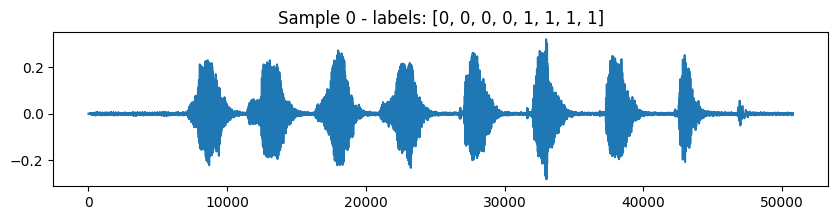

In [3]:
import os
os.makedirs("./data", exist_ok=True)

import torch, torchaudio
from torchaudio.datasets import YESNO
import matplotlib.pyplot as plt

dataset = YESNO(root="./data", download=True)

print("عدد التسجيلات:", len(dataset))

waveform, sr, labels = dataset[0]
print("معدل العينة:", sr)
print("شكل الإشارة:", waveform.shape)
print("التسميات (8 كلمات):", labels)

plt.figure(figsize=(10, 2))
plt.plot(waveform[0].numpy())
plt.title(f"Sample 0 - labels: {labels}")
plt.show()

In [4]:
import numpy as np
import torch
import torch.nn.functional as F
import torchaudio
from torchaudio.datasets import YESNO

dataset = YESNO(root="./data", download=True)

mfcc = torchaudio.transforms.MFCC(
    sample_rate=8000,
    n_mfcc=20,
    melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 40},
)

X3, Y = [], []
for waveform, sr, labels in dataset:
    feat = mfcc(waveform).squeeze(0)                        # (20, frames)
    pooled = F.adaptive_avg_pool1d(feat.unsqueeze(0), 64)   # (1, 20, 64)
    X3.append(pooled.squeeze(0).numpy())
    Y.append(labels)

X3 = np.stack(X3)            # (60, 20, 64)  للشبكة العصبية CNN
X = X3.reshape(len(X3), -1)  # (60, 1280)    للمصنفات التقليدية
Y = np.array(Y)              # (60, 8)

print("X3:", X3.shape)
print("X:", X.shape)
print("Y:", Y.shape)
print("أول تسميات:", Y[0])

X3: (60, 20, 64)
X: (60, 1280)
Y: (60, 8)
أول تسميات: [0 0 0 0 1 1 1 1]


In [5]:
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
import numpy as np

def cv_eval(fit_predict, X, Y, seed=0):
    kf = KFold(n_splits=5, shuffle=True, random_state=seed)
    bit_acc, seq_acc = [], []
    for tr, te in kf.split(X):
        pred = fit_predict(X[tr], Y[tr], X[te])
        bit_acc.append((pred == Y[te]).mean())
        seq_acc.append((pred == Y[te]).all(axis=1).mean())
    return np.mean(bit_acc), np.mean(seq_acc)

def sk_fit_predict(model):
    def f(Xtr, Ytr, Xte):
        m = clone(model)
        m.fit(Xtr, Ytr)
        return m.predict(Xte)
    return f

sk_models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        MultiOutputClassifier(LogisticRegression(max_iter=3000))),
    "SVM (RBF)": make_pipeline(
        StandardScaler(),
        MultiOutputClassifier(SVC(kernel="rbf", C=1.0))),
    "KNN (k=3)": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=3)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=0),
    "MLP (sklearn)": make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(128,), max_iter=2000, random_state=0)),
}

results = {}
for name, model in sk_models.items():
    results[name] = cv_eval(sk_fit_predict(model), X, Y)
    print(f"{name}: done")

print("Classical models finished.")

Logistic Regression: done
SVM (RBF): done
KNN (k=3): done
Random Forest: done
MLP (sklearn): done
Classical models finished.


In [9]:
import torch
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(20, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool1d(2),
            nn.Flatten(),                 # 64 قناة × 16 إطاراً زمنياً = 1024
            nn.Dropout(0.3),
            nn.Linear(64 * 16, 8),
        )

    def forward(self, x):
        return self.net(x)

def cnn_fit_predict(Xtr, Ytr, Xte, epochs=150, batch=8, lr=1e-3):
    torch.manual_seed(0)
    mu = Xtr.mean(axis=(0, 2), keepdims=True)
    sd = Xtr.std(axis=(0, 2), keepdims=True) + 1e-8
    Xtr_t = torch.tensor((Xtr - mu) / sd, dtype=torch.float32)
    Xte_t = torch.tensor((Xte - mu) / sd, dtype=torch.float32)
    Ytr_t = torch.tensor(Ytr, dtype=torch.float32)

    model = CNN()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()

    model.train()
    for _ in range(epochs):
        perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = loss_fn(model(Xtr_t[idx]), Ytr_t[idx])
            loss.backward()
            opt.step()

    model.eval()
    with torch.no_grad():
        probs = torch.sigmoid(model(Xte_t))
    return (probs > 0.5).int().numpy()

print("Training CNN...")
results["CNN (PyTorch)"] = cv_eval(cnn_fit_predict, X3, Y)
print("CNN finished.")

print(f"{'Classifier':<22}{'Bit Acc':>10}{'Seq Acc':>10}")
for name, (bit, seq) in sorted(results.items(), key=lambda kv: -kv[1][0]):
    print(f"{name:<22}{bit:>10.3f}{seq:>10.3f}")

Training CNN...
CNN finished.
Classifier               Bit Acc   Seq Acc
CNN (PyTorch)              0.942     0.767
Logistic Regression        0.852     0.383
MLP (sklearn)              0.783     0.117
Random Forest              0.762     0.067
SVM (RBF)                  0.713     0.083
KNN (k=3)                  0.679     0.050


In [10]:
seeds = [0, 1, 2]
summary = {}

for name, model in sk_models.items():
    runs = [cv_eval(sk_fit_predict(model), X, Y, seed=s) for s in seeds]
    summary[name] = np.array(runs)

cnn_runs = [cv_eval(cnn_fit_predict, X3, Y, seed=s) for s in seeds]
summary["CNN (PyTorch)"] = np.array(cnn_runs)

print(f"{'Classifier':<22}{'Bit Acc (mean±std)':>22}{'Seq Acc (mean±std)':>22}")
for name, arr in sorted(summary.items(), key=lambda kv: -kv[1][:, 0].mean()):
    b, s = arr[:, 0], arr[:, 1]
    print(f"{name:<22}{b.mean():>12.3f} ± {b.std():.3f}{s.mean():>12.3f} ± {s.std():.3f}")

Classifier                Bit Acc (mean±std)    Seq Acc (mean±std)
CNN (PyTorch)                0.945 ± 0.008       0.789 ± 0.031
Logistic Regression          0.860 ± 0.006       0.411 ± 0.021
MLP (sklearn)                0.787 ± 0.003       0.128 ± 0.008
Random Forest                0.740 ± 0.020       0.056 ± 0.016
SVM (RBF)                    0.689 ± 0.018       0.061 ± 0.016
KNN (k=3)                    0.674 ± 0.012       0.028 ± 0.016


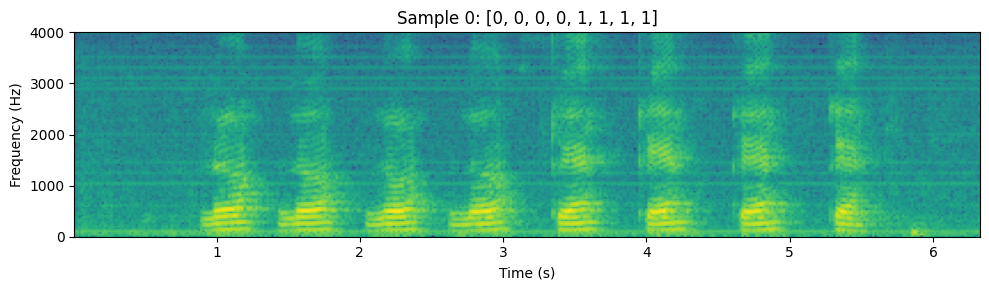

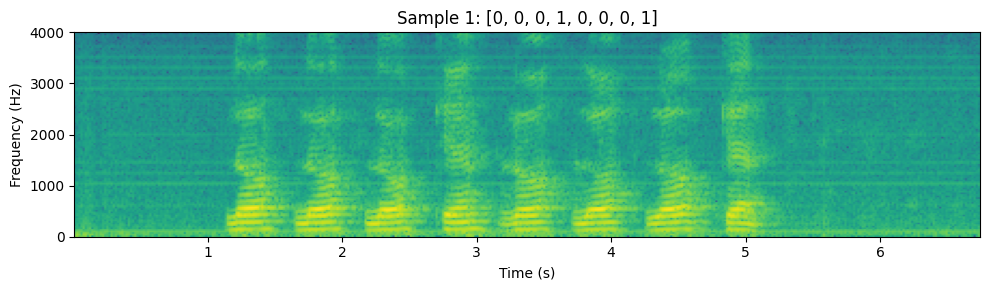

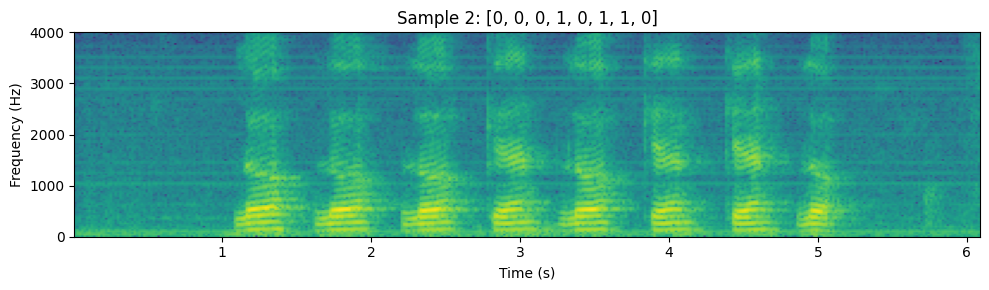

In [11]:
import matplotlib.pyplot as plt

def plot_specgram(waveform, sample_rate, title="Spectrogram"):
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.specgram(waveform[0].numpy(), Fs=sample_rate)
    ax.set_title(title)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Frequency (Hz)")
    fig.tight_layout()
    plt.show()

for i in [0, 1, 2]:
    waveform, sr, labels = dataset[i]
    plot_specgram(waveform, sr, title=f"Sample {i}: {labels}")

In [12]:
print("| Classifier | Bit Acc (mean ± std) | Seq Acc (mean ± std) |")
print("|---|---|---|")
for name, arr in sorted(summary.items(), key=lambda kv: -kv[1][:, 0].mean()):
    b, s = arr[:, 0], arr[:, 1]
    print(f"| {name} | {b.mean():.3f} ± {b.std():.3f} | {s.mean():.3f} ± {s.std():.3f} |")

| Classifier | Bit Acc (mean ± std) | Seq Acc (mean ± std) |
|---|---|---|
| CNN (PyTorch) | 0.945 ± 0.008 | 0.789 ± 0.031 |
| Logistic Regression | 0.860 ± 0.006 | 0.411 ± 0.021 |
| MLP (sklearn) | 0.787 ± 0.003 | 0.128 ± 0.008 |
| Random Forest | 0.740 ± 0.020 | 0.056 ± 0.016 |
| SVM (RBF) | 0.689 ± 0.018 | 0.061 ± 0.016 |
| KNN (k=3) | 0.674 ± 0.012 | 0.028 ± 0.016 |
